# Lab 07 — Talking to the Model
### From a saved checkpoint to a reliable chat loop

**English · Guided lecture and executable practical · Three sessions of 75–90 minutes**

A chat interface is the final connection between the language model and a person. The interface must reconstruct the right model, encode a prompt in the format it learned, generate a bounded continuation, and present the result without confusing prompt text with model output. None of those steps improves the model's knowledge by itself.

This lab follows **Step 7: Talking to the Model** in [FareedKhan-dev/train-llm-from-scratch](https://github.com/FareedKhan-dev/train-llm-from-scratch#step-7-talking-to-the-model). It continues directly from Labs 03–06: use the saved files, do not retrain, and do not embed checkpoint weights in the notebook.

### Learning outcomes

By the end, you will be able to:
1. Explain raw continuation versus an assistant response as different conditional-generation problems.
2. Reconstruct a policy from its checkpoint and validate its tokenizer and prompt contract.
3. Implement greedy and sampled decoding with explicit stop reasons and token budgets.
4. Build one-shot and interactive interfaces over the same inference function.
5. Explain why the repository's interactive CLI is stateless, then implement a labelled multi-turn extension.
6. Trim complete historical turns while preserving the current question and a response budget.
7. Test reproducibility, error recovery, context overflow, and the absence of weight updates.
8. Save a session receipt and connect qualitative chat observations back to Lab 06 evaluation.

### Two execution tracks

| Track | Model and template | Purpose |
|---|---|---|
| A — executed CPU practical | Lab 03 ASCII base; Lab 05 SFT/DPO/PPO/GRPO; compact `U:...\nA:` | Build and test inference and session management with real saved weights |
| B — actual repository | Repository checkpoints; `r50k_base`; repository role markers and EOT | Run `scripts/chat.py` and its actual Python API |

The tiny Track A model has a **24-token context** and was trained on compact addition examples. It is not a general conversational assistant. Multi-turn prompts are outside its single-turn training distribution. We can verify the software preserves history without claiming the model understands that history.

The teaching pattern is explanation → equations → small components → contract tests → real-model observations → independent exercises. This is original instructional material, not an official university assignment.


## 1. Source map and boundaries

Sources inspected on **14 November 2026**. The values below are Git **blob** IDs, identifying file contents rather than entire repository commits.

| Source | Responsibility | Inspected blob |
|---|---|---|
| [scripts/chat.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/scripts/chat.py) | One-shot prompt, interactive loop, options, device and int8 setup | `67e3fb1b9b178c96dc8f47446d09b88faf2e6174` |
| [post_training/inference.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/inference.py) | Checkpoint loader and `generate_reply` | `1ba2b77aec59a1858992d72644c809d456e5daf2` |
| [post_training/chat_template.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/chat_template.py) | Ordinary-text role markers, tokenization, EOT, display rendering | `41bfd87cd95eb6abd96bf23351671bab70054e4c` |
| [post_training/evaluation.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/evaluation.py) | Shared generation path with Step 6 | `478f8c6b5b2b24b66cfada6b3a4d4cfd2c62e51e` |
| [post_training/rollout.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/rollout.py) | Autoregressive loop, per-row EOT stopping, modern-model cache |
| [inference/sampling.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/inference/sampling.py) | Temperature and probability filters | `e3ff9ee2e5b52fa780117cada234426ac897060b` |
| [inference/quantize.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/inference/quantize.py) | Optional int8 linear-weight storage | `461b2904251fa772e7d3097153a225bd9429aa0c` |
| [device.py](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/device.py) | Automatic and explicit device selection | `b192a0193268675371876919eee6b6f669a58e74` |

**Repository behavior:** `generate_reply` constructs a new system/user message list for each call. Its CLI repeats that call without accumulating previous messages. An interactive terminal is therefore not automatically a multi-turn conversation.

**Lab additions:** explicit finish reasons, strict parameter validation, a stateful session, whole-turn pruning, reset/history commands, transcripts, and contract tests. These are extensions, not claims about features already implemented in `scripts/chat.py`.


## 2. The idea: chat is conditioned continuation

The trained model supplies a next-token distribution. It does not receive a Python `role` object; it receives token IDs produced by a serializer.

For a tokenized prompt $x_{1:P}$ and response $y_{1:T}$:

$$p_\theta(y_{1:T}\mid x_{1:P})=\prod_{t=1}^{T}p_\theta(y_t\mid x_{1:P},y_{<t}).$$

In **raw mode**, the prompt might be `Once upon a time`. The model continues that text. In **chat mode**, the prompt includes learned role markers and a trailing assistant header. The model continues the assistant portion.

| Layer | What it knows | What it does not guarantee |
|---|---|---|
| Checkpoint | Learned weights and architecture settings | Instruction following |
| Tokenizer | Text-to-ID correspondence | Meaningful answers |
| Chat template | The serialization convention seen in training | Role compliance by an undertrained model |
| Decoder | How the next token is selected | Correct reasoning |
| Session manager | Which previous turns are included | Long-term memory or additional training |

A system message is input context, not a weight update. The model can only exploit that convention if training taught it how. Switching `raw=False` does not turn a base model into an instruction model.

**Check your understanding:** if two calls use identical weights and identical user text but different templates, are they the same experiment? No: their token prefixes differ, so their conditional distributions can differ.


## 3. Load actual checkpoints from the preceding labs

Install `torch`, `numpy`, and `matplotlib` in your notebook environment if needed. Run from the directory containing your earlier `lab03_runs` and `lab05_runs` folders.

Set `LAB05_DIR` to your completed Lab 05 run. The example value below is the run used for the included outputs. The base checkpoint comes from its recorded source; use `BASE_PATH_OVERRIDE` if you moved that file. Set `LAB06_MANIFEST` if you also want to verify that the checkpoints match a specific Lab 06 evaluation.

Only use checkpoint files you created or trust. We load with `weights_only=True`, validate metadata, and load state dictionaries strictly. No missing file is replaced with a randomly initialized model. `reward.pt` is not a policy stage to add to this comparison.


In [1]:
import copy, json, math, hashlib, tempfile, time, sys, subprocess, re
from pathlib import Path
from dataclasses import dataclass, asdict
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

torch.set_num_threads(1)
torch.manual_seed(42)
DEVICE = "cpu"
LAB05_DIR = Path("lab05_runs/run_46tulole")  # Change to YOUR completed run.
BASE_PATH_OVERRIDE = None
LAB06_MANIFEST = None  # Optional: Path("lab06_runs/<your_run>/manifest.json")
STAGES = ("base", "sft", "dpo", "ppo", "grpo")
EXPECTED_TOKENIZER = {"kind":"ascii-character", "vocab_size":129, "eot_id":128}
EOT, VOCAB_SIZE = 128,129
for stage in STAGES[1:]:
    if not (LAB05_DIR/f"{stage}.pt").is_file():
        raise FileNotFoundError(f"Missing {stage}.pt. Set LAB05_DIR or complete Lab 05 first.")
sft_meta = torch.load(LAB05_DIR/"sft.pt", map_location="cpu", weights_only=True)
BASE_PATH = Path(BASE_PATH_OVERRIDE or sft_meta["source_checkpoint"])
CHECKPOINTS = {"base":BASE_PATH, **{s:LAB05_DIR/f"{s}.pt" for s in STAGES[1:]}}

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""): h.update(block)
    return h.hexdigest()

CHECKPOINT_HASHES = {s:sha256_file(p) for s,p in CHECKPOINTS.items()}
if LAB06_MANIFEST is not None:
    previous = json.loads(Path(LAB06_MANIFEST).read_text())
    for stage in STAGES:
        assert previous["checkpoints"][stage]["sha256"] == CHECKPOINT_HASHES[stage]
Path("lab07_runs").mkdir(exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="chat_",dir="lab07_runs"))
print("PyTorch:",torch.__version__,"| device:",DEVICE)
print("Checkpoint files:",{s:str(p) for s,p in CHECKPOINTS.items()})
print("Session artifacts:",RUN_DIR)


PyTorch: 2.15.0+cpu | device: cpu
Checkpoint files: {'base': 'lab03_runs/run_pvg4r57e/final.pt', 'sft': 'lab05_runs/run_46tulole/sft.pt', 'dpo': 'lab05_runs/run_46tulole/dpo.pt', 'ppo': 'lab05_runs/run_46tulole/ppo.pt', 'grpo': 'lab05_runs/run_46tulole/grpo.pt'}
Session artifacts: /workspace/scratch/d20f4a09d498/lab07_runs/chat_5o39lhqo


### 3.1 Reconstruct the same architecture

The following definitions are reused from Lab 03. They allocate the modules into which the saved weights are loaded; they do not train a replacement model. The learning objective in this lab is the inference interface, so you do not need to reimplement attention here.


In [2]:
class MLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.hidden = nn.Linear(width, 4 * width)
        self.proj = nn.Linear(4 * width, width)

    def forward(self, x):
        return self.proj(F.relu(self.hidden(x)))

def causal_attention(q, k, v):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    length = q.shape[-2]
    allowed = torch.ones(length, length, dtype=torch.bool, device=q.device).tril()
    weights = scores.masked_fill(~allowed, float("-inf")).softmax(dim=-1)
    return weights @ v, weights

class Head(nn.Module):
    def __init__(self, width, head_width):
        super().__init__()
        self.query = nn.Linear(width, head_width, bias=False)
        self.key = nn.Linear(width, head_width, bias=False)
        self.value = nn.Linear(width, head_width, bias=False)

    def forward(self, x):
        output, _ = causal_attention(self.query(x), self.key(x), self.value(x))
        return output

class MultiHeadAttention(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        if width % heads:
            raise ValueError("Embedding width must be divisible by head count.")
        self.heads = nn.ModuleList([Head(width, width // heads) for _ in range(heads)])
        self.proj = nn.Linear(width, width)

    def forward(self, x):
        return self.proj(torch.cat([head(x) for head in self.heads], dim=-1))

class Block(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(width)
        self.attn = MultiHeadAttention(width, heads)
        self.ln2 = nn.LayerNorm(width)
        self.mlp = MLP(width)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class Transformer(nn.Module):
    def __init__(self, vocab_size, width, heads, context_length, layers):
        super().__init__()
        self.context_length = context_length
        self.token_embed = nn.Embedding(vocab_size, width)
        self.position_embed = nn.Embedding(context_length, width)
        self.blocks = nn.ModuleList([Block(width, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(width)
        self.lm_head = nn.Linear(width, vocab_size)

    def forward_hidden(self, ids):
        length = ids.shape[1]
        if not 1 <= length <= self.context_length:
            raise ValueError("Sequence length is outside the supported context.")
        positions = torch.arange(length, device=ids.device)
        hidden = self.token_embed(ids) + self.position_embed(positions)
        for block in self.blocks:
            hidden = block(hidden)
        return self.norm(hidden)

    def forward(self, ids, targets=None):
        logits = self.lm_head(self.forward_hidden(ids))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1).long())
        return logits, loss


In [3]:
def load_lab_policy(path,stage):
    checkpoint = torch.load(path,map_location="cpu",weights_only=True)
    if checkpoint.get("tokenizer") != EXPECTED_TOKENIZER:
        raise ValueError("Use the repository loader for BPE checkpoints; this loader requires Lab ASCII.")
    if stage != "base":
        if checkpoint.get("stage") != stage: raise ValueError("Stage label mismatch")
        if checkpoint.get("chat_template") != "U:{a}+{b}\nA:": raise ValueError("Template mismatch")
    cfg = checkpoint["config"]
    model = Transformer(VOCAB_SIZE,cfg["width"],cfg["heads"],cfg["context_length"],cfg["layers"])
    model.load_state_dict(checkpoint["model_state"],strict=True)
    return model.to(DEVICE).eval().requires_grad_(False),checkpoint

models,metadata = {},{}
for stage,path in CHECKPOINTS.items():
    models[stage],metadata[stage] = load_lab_policy(path,stage)
for stage in STAGES[1:]:
    for field in ("width","heads","layers","context_length"):
        assert metadata[stage]["config"][field] == metadata["base"]["config"][field]
    source = Path(metadata[stage]["source_checkpoint"])
    if source.exists(): assert sha256_file(source) == CHECKPOINT_HASHES["base"]

def model_digest(model):
    h = hashlib.sha256()
    for name,tensor in sorted(model.state_dict().items()):
        h.update(name.encode())
        h.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

WEIGHTS_BEFORE = {stage:model_digest(model) for stage,model in models.items()}
print("Loaded",len(models),"policies with context",models["sft"].context_length)
print("Parameters:",sum(p.numel() for p in models["sft"].parameters()))


Loaded 5 policies with context 24
Parameters: 34433


## 4. Serialize messages exactly as training expects

The repository's chat serialization uses ordinary-text headers `<|system|>\n`, `<|user|>\n`, `<|assistant|>\n`. They are **not dedicated special token IDs**. Content is encoded with `encode_ordinary`, and each completed message receives the actual EOT token ID **50256**. Generation begins after an unfinished assistant header.

Track A must instead preserve Lab 05's compact single-turn contract:

```text
U:1+2
A:
```

The expected continuation is `3` followed by ASCII-lab EOT **128**. Adding repository role markers would change the input distribution and consume most of the tiny context window. We therefore reject system messages in the compact adapter instead of quietly inventing a format.

For the optional multi-turn extension, we concatenate completed compact user/assistant exchanges, placing EOT after each assistant response. The current user message ends with an assistant header. This extension is mechanically well-defined but was not part of the tiny model's training.

**Important:** a display placeholder such as `<EOT>` is not the same thing as an EOT token. Store IDs and structured messages; use rendered text only for inspection. In the repository, tokenizing `render_chat(...)` as ordinary text would turn the displayed EOT string into ordinary tokens. Use `encode_prompt(...)` instead.


In [4]:
def encode_ascii(text):
    if not isinstance(text,str) or any(ord(c)>=EOT for c in text):
        raise ValueError("Track A accepts ASCII text only; use the repository tokenizer for other text.")
    return [ord(c) for c in text]

def decode_ascii(ids):
    return "".join(chr(i) for i in ids if 0 <= i < EOT)

def validate_messages(messages):
    if not messages: raise ValueError("A prompt needs a current user message.")
    for i,message in enumerate(messages):
        expected = "user" if i%2==0 else "assistant"
        if message.get("role") != expected: raise ValueError("Expected alternating user/assistant roles, starting with user.")
        if not isinstance(message.get("content"),str) or not message["content"].strip():
            raise ValueError("Messages must contain nonempty text.")
    if messages[-1]["role"] != "user": raise ValueError("Generation prompt must end with a user turn.")

def compact_prompt_ids(messages):
    validate_messages(messages)
    ids = []
    for message in messages:
        if message["role"] == "user":
            ids += encode_ascii("U:"+message["content"]+"\nA:")
        else:
            ids += encode_ascii(message["content"])+[EOT]
    return ids

def visible_ids(ids):
    return "".join("<EOT>" if t == EOT else chr(t) for t in ids)

single = [{"role":"user","content":"1+2"}]
assert compact_prompt_ids(single) == encode_ascii("U:1+2\nA:")
example_history = [{"role":"user","content":"1+2"},{"role":"assistant","content":"3"},
                   {"role":"user","content":"2+1"}]
print("Single-turn prefix:",repr(visible_ids(compact_prompt_ids(single))))
print("Multi-turn extension:",repr(visible_ids(compact_prompt_ids(example_history))))
print("Single/history lengths:",len(compact_prompt_ids(single)),len(compact_prompt_ids(example_history)))


Single-turn prefix: 'U:1+2\nA:'
Multi-turn extension: 'U:1+2\nA:3<EOT>U:2+1\nA:'
Single/history lengths: 8 18


## 5. Decoding controls: from logits to a token

For logits $z_v$ and positive temperature $\tau$:

$$p_\tau(v)=\frac{\exp(z_v/\tau)}{\sum_u\exp(z_u/\tau)}.$$

Lower temperature concentrates probability; higher temperature spreads it out. It does not add facts or repair incorrect reasoning. Greedy decoding chooses $\arg\max_v z_v$ directly and ignores temperature and sampling filters.

**Top-k** removes tokens below the k-th largest logit. A threshold implementation can retain more than k tokens when logits tie. **Top-p** sorts the remaining probabilities and keeps the smallest prefix that reaches or exceeds p. The token that crosses the threshold must be retained; otherwise you can remove too much probability mass.

We apply temperature → top-k → top-p, then renormalize with softmax. The repository's shared sampler also supports min-p, but **`scripts/chat.py` does not expose a `--min_p` flag**. We focus on the flags available in Step 7.

Our lab uses explicit `argmax` for greedy selection. The repository chat path goes through `batched_generate`, where greedy is implemented using top-k=1 followed by sampling. With a unique maximum these agree; threshold ties may retain several tokens. This distinction is worth testing rather than assuming all functions named “greedy” are identical.


In [5]:
@dataclass(frozen=True)
class DecodeConfig:
    max_new_tokens: int = 4
    greedy: bool = True
    temperature: float = 0.8
    top_k: int | None = None
    top_p: float | None = 0.95
    seed: int = 42

    def validate(self):
        if not isinstance(self.max_new_tokens,int) or self.max_new_tokens < 1:
            raise ValueError("max_new_tokens must be a positive integer.")
        if not math.isfinite(self.temperature) or self.temperature <= 0:
            raise ValueError("temperature must be positive and finite; use greedy=True for argmax.")
        if self.top_k is not None and (not isinstance(self.top_k,int) or self.top_k < 1):
            raise ValueError("top_k must be None or a positive integer.")
        if self.top_p is not None and not 0 < self.top_p <= 1:
            raise ValueError("top_p must be None or in (0,1].")

def filtered_logits(logits,config):
    config.validate()
    scores = logits.float().clone()/config.temperature
    if config.top_k is not None:
        k = min(config.top_k,scores.shape[-1])
        cutoff = scores.topk(k,dim=-1).values[...,-1,None]
        scores = scores.masked_fill(scores < cutoff,-float("inf"))
    if config.top_p is not None and config.top_p < 1:
        ordered,index = scores.sort(dim=-1,descending=True)
        remove = ordered.softmax(-1).cumsum(-1) > config.top_p
        remove[...,1:] = remove[...,:-1].clone()
        remove[...,0] = False
        scores = scores.masked_fill(torch.zeros_like(remove).scatter(-1,index,remove),-float("inf"))
    return scores

def select_next(logits,config,generator):
    if not torch.isfinite(logits).all(): raise ValueError("Non-finite model logits")
    if config.greedy: return logits.argmax(-1,keepdim=True)
    return torch.multinomial(filtered_logits(logits,config).softmax(-1),1,generator=generator)

logits = torch.log(torch.tensor([[0.50,0.30,0.15,0.05]]))
nucleus = DecodeConfig(greedy=False,temperature=1,top_p=0.7)
assert torch.isfinite(filtered_logits(logits,nucleus)).tolist() == [[True,True,False,False]]
assert torch.isfinite(filtered_logits(logits,DecodeConfig(top_k=1,top_p=None))).sum() == 1
assert torch.isfinite(filtered_logits(torch.zeros(1,4),DecodeConfig(top_k=1,top_p=None))).sum() == 4
for tau in (0.5,1.0,2.0):
    probs = (logits/tau).softmax(-1)[0]
    print("temperature",tau,"probabilities",[round(p,3) for p in probs.tolist()])
print("Filter threshold and tie tests passed.")


temperature 0.5 probabilities [0.685, 0.247, 0.062, 0.007]
temperature 1.0 probabilities [0.5, 0.3, 0.15, 0.05]
temperature 2.0 probabilities [0.379, 0.294, 0.208, 0.12]
Filter threshold and tie tests passed.


## 6. One inference function, two front ends

The model produces logits of shape `[batch, sequence, vocabulary]`. At each step we read only `logits[:, -1, :]`, select one token, append it, and stop at EOT or the allowed length. The returned text contains **only generated tokens**, never the original prompt.

For context capacity $C$, prefix length $P$, and requested maximum $M$:

$$B=\min(M,C-P).$$

This follows the no-rollover policy used by the repository's chat/evaluation path. It differs from a generation method that repeatedly discards old prefix tokens. If $P\ge C$, our lab raises a clear context error; the repository's `batched_generate` returns an empty response. We deliberately make the application error distinguishable from a model that immediately emits EOT.

`model.eval()` controls training-specific layers; `torch.inference_mode()` disables autograd bookkeeping. Neither replaces the other. We restore the caller's model mode after inference and verify the weights remain unchanged.

We use a request-local random generator on CPU. Repeating the same seed, prefix and configuration should reproduce sampled output in this environment. It does not guarantee identical outputs on another backend or library version. A fixed seed per request is an experimental choice; increment it when deliberately sampling alternatives.


In [6]:
@dataclass
class Reply:
    text: str
    token_ids: list[int]
    prompt_tokens: int
    generated_tokens: int
    budget: int
    finish_reason: str
    elapsed_seconds: float

class ContextBudgetError(ValueError):
    pass

@torch.inference_mode()
def generate_reply_ids(model,prompt_ids,config):
    config.validate()
    if not prompt_ids: raise ValueError("Empty prefix: supply text or an explicit beginning token.")
    if any(not isinstance(t,int) or not 0 <= t < VOCAB_SIZE for t in prompt_ids):
        raise ValueError("Invalid Lab token ID.")
    budget = min(config.max_new_tokens,model.context_length-len(prompt_ids))
    if budget <= 0: raise ContextBudgetError("The prefix leaves no room for a response.")
    device = next(model.parameters(),torch.empty(0)).device
    if device.type != "cpu": raise ValueError("This reference loop is CPU-only; use Track B for device-aware repository inference.")
    generator = torch.Generator(device="cpu").manual_seed(config.seed)
    sequence = torch.tensor([prompt_ids],dtype=torch.long,device=device)
    generated,finish = [],"length"
    previous_mode = model.training
    model.eval()
    started = time.perf_counter()
    try:
        for _ in range(budget):
            logits = model(sequence)[0][:,-1,:]
            token = int(select_next(logits,config,generator).item())
            generated.append(token)
            sequence = torch.cat([sequence,torch.tensor([[token]],device=device)],dim=1)
            if token == EOT:
                finish = "eot"
                break
    finally:
        model.train(previous_mode)
    visible = generated[:-1] if finish == "eot" else generated
    return Reply(decode_ascii(visible),generated,len(prompt_ids),len(generated),budget,
                 finish,time.perf_counter()-started)

def reply_once(stage,text,config=DecodeConfig(),raw=False,system=None):
    if stage not in models: raise ValueError(f"Unknown stage: {stage}")
    if not isinstance(text,str) or not text.strip(): raise ValueError("Enter nonempty text.")
    if system is not None: raise ValueError("The compact Lab template has no system role. Use Track B.")
    prefix = encode_ascii(text) if raw else compact_prompt_ids([{"role":"user","content":text}])
    return generate_reply_ids(models[stage],prefix,config)

reply = reply_once("sft","1+2")
print("Response:",repr(reply.text),"| details:",asdict(reply))
print("Raw base continuation:",repr(reply_once("base","The ",DecodeConfig(max_new_tokens=12),raw=True).text))


Response: '3' | details: {'text': '3', 'token_ids': [51, 128], 'prompt_tokens': 8, 'generated_tokens': 2, 'budget': 4, 'finish_reason': 'eot', 'elapsed_seconds': 0.003351491000103124}
Raw base continuation: 'arend a a ad'


### 6.1 Contract tests before interactive use

A scripted policy below produces predetermined tokens solely to test the inference machinery. It is not used for model-quality demonstrations. We verify an immediate stop, a length-limited response, a prefix with no remaining budget, mode restoration, and a real-policy seeded replay.

A single new token can be a correct digit while there is no budget left for EOT. Therefore “correct answer” and “proper termination” are separate observations, as in Lab 06.


In [7]:
class FixedTokenPolicy(nn.Module):
    context_length = 24
    def __init__(self,token):
        super().__init__(); self.token=token
    def forward(self,ids):
        logits = torch.full((*ids.shape,VOCAB_SIZE),-1000.0,device=ids.device)
        logits[:,:,-1] = -1000
        logits[:,:,self.token] = 1000
        return logits,None

prefix = compact_prompt_ids([{"role":"user","content":"1+2"}])
stop_model = FixedTokenPolicy(EOT).train()
stop_reply = generate_reply_ids(stop_model,prefix,DecodeConfig())
assert stop_reply.text == "" and stop_reply.token_ids == [EOT] and stop_reply.finish_reason == "eot"
assert stop_model.training
limited = generate_reply_ids(FixedTokenPolicy(ord("3")),prefix,DecodeConfig(max_new_tokens=2))
assert limited.text == "33" and limited.finish_reason == "length"
try:
    generate_reply_ids(stop_model,[1]*24,DecodeConfig())
    raise AssertionError("Expected overflow rejection")
except ContextBudgetError: pass
sample_config = DecodeConfig(greedy=False,temperature=1.2,top_k=20,top_p=0.95,seed=17)
a,b = reply_once("sft","0+1",sample_config),reply_once("sft","0+1",sample_config)
assert a.token_ids == b.token_ids
assert all(p.grad is None for model in models.values() for p in model.parameters())
for invalid in (DecodeConfig(temperature=0),DecodeConfig(top_p=0),DecodeConfig(max_new_tokens=0)):
    try:
        invalid.validate()
        raise AssertionError("Invalid decoding setting accepted")
    except ValueError: pass
try:
    select_next(torch.tensor([[float("nan"),0.0]]),DecodeConfig(),None)
    raise AssertionError("Non-finite logits accepted")
except ValueError: pass
unique_logits=torch.tensor([[1.0,3.0,2.0]])
for temperature in (0.1,1.0,10.0):
    assert int(select_next(unique_logits,DecodeConfig(temperature=temperature),None))==1
print("EOT, length cap, context error, mode restoration, seeded replay, invalid settings and greedy invariance: passed")


EOT, length cap, context error, mode restoration, seeded replay, invalid settings and greedy invariance: passed


## 7. Observe real stage behavior without inventing success

First compare all stages on the **same compact prompt**, with greedy decoding and the same token budget. Include both a training pair (`1+2`) and a reused validation pair (`0+1`). This is a diagnostic, not a new independent benchmark.

Then inspect raw base continuation separately. It has a different prompt contract and should not be mixed into the numerical chat comparison. The expected lesson is that post-training can change the response format without producing reliable arithmetic generalization.

Do not add an external arithmetic calculator or repair the model's answer before displaying it. Such a tool-augmented system can be useful, but it would measure a different system and conceal the behavior we are studying.


In [8]:
observations=[]
for question in ("1+2","0+1"):
    for stage in STAGES:
        result = reply_once(stage,question,DecodeConfig(max_new_tokens=4))
        row={"stage":stage,"question":question,"mode":"compact_chat",**asdict(result)}
        observations.append(row)
        print(f"{stage:5} | {question:3} | {result.text!r:12} | {result.finish_reason:6} | tokens={result.generated_tokens}")
raw_result = reply_once("base","The ",DecodeConfig(max_new_tokens=12),raw=True)
observations.append({"stage":"base","question":"The ","mode":"raw",**asdict(raw_result)})
print("Raw base prefix 'The ' ->",repr(raw_result.text))


base  | 1+2 | 'nd a'       | length | tokens=4
sft   | 1+2 | '3'          | eot    | tokens=2
dpo   | 1+2 | '3'          | eot    | tokens=2
ppo   | 1+2 | '3'          | eot    | tokens=2
grpo  | 1+2 | '3'          | eot    | tokens=2
base  | 0+1 | 'nd a'       | length | tokens=4
sft   | 0+1 | '2'          | eot    | tokens=2
dpo   | 0+1 | '1'          | eot    | tokens=2
ppo   | 0+1 | '2'          | eot    | tokens=2
grpo  | 0+1 | '2'          | eot    | tokens=2
Raw base prefix 'The ' -> 'arend a a ad'


### 7.1 A controlled sampling experiment

Keep the checkpoint and input fixed while varying the decoding configuration. Use the same list of seeds for each sampled configuration. Observe repetition, format, stopping, and diversity. Different seeds are not guaranteed to yield different answers if the distribution is concentrated.

This experiment intentionally uses the weak base model's raw continuation to make distribution changes visible. More variety does not mean more correctness. A small subjective selection of fluent samples cannot replace the fixed evaluations from Lab 06.


In [9]:
sampling_rows=[]
for label,temperature in (("cool",0.5),("default",0.8),("warm",1.3)):
    for seed in (1,2,3):
        cfg=DecodeConfig(max_new_tokens=12,greedy=False,temperature=temperature,top_k=20,top_p=0.95,seed=seed)
        result=reply_once("base","The ",cfg,raw=True)
        sampling_rows.append({"setting":label,"config":asdict(cfg),**asdict(result)})
        print(label,"seed",seed,"->",repr(result.text),"|",result.finish_reason)


cool seed 1 -> 'and a a ad a' | length
cool seed 2 -> 'arend a ad a' | length
cool seed 3 -> 'ary.' | eot
default seed 1 -> 'and ato ry.' | eot
default seed 2 -> 'weren and at' | length
default seed 3 -> 'ary.' | eot
warm seed 1 -> 'scirand ryd ' | length
warm seed 2 -> 'ware panyend' | length
warm seed 3 -> 'markend a at' | length


## 8. Stateless interaction versus remembered conversation

The inspected repository loop calls `generate_reply(model, text, ...)` independently for each user line. That function creates at most a system message and the current user message. The previous response is not automatically sent back.

For a stateful extension, let $H_t$ be retained completed turns before the current request $u_t$. The next reply is conditioned on

$$x_t=T(H_t\mathbin{\|}[u_t]),\qquad r_t\sim G(\pi_\theta,x_t).$$

After a successful completed reply:

$$H_{t+1}=\operatorname{kept}(H_t)\mathbin{\|}[(u_t,r_t)].$$

The session manager owns $H_t$. Model parameters stay fixed. A KV cache can accelerate computation on a prefix, but it is not a substitute for deciding what belongs in the conversation. The repository's modern-model rollout cache is created inside generation; the stateless CLI does not persist a conversation cache across separate calls.

### A transaction policy for this lab

1. Validate the new input and prepare a candidate history without changing session state.
2. Prune old completed pairs if necessary.
3. Generate a reply.
4. Commit only a **nonempty EOT-terminated** response.
5. If generation fails, is empty, or reaches its length cap, return/report that condition and leave history unchanged.

This conservative policy avoids recording a truncated reply as a complete turn. Other policies are possible; for example, a UI can let the user explicitly accept a partial response. The choice must be explicit and tested.


## 9. Context budgeting without breaking turns

Reserve the requested response budget before generation:

$$P_{\max}=C-M,\qquad |T(H,u)|\le P_{\max}.$$

If a candidate is too long, remove the oldest **user + assistant pair** and re-encode. Always preserve the newest user message. If the newest message alone cannot fit, reject it and ask for a shorter message or smaller budget. Do not silently chop off the user's question or replace it with a summary in this lab.

With the compact template, a one-digit addition prompt has 8 tokens. A completed one-digit exchange has 10 tokens including EOT. With $C=24$ and $M=4$, one prior exchange plus the current prompt uses 18 tokens and fits. Two prior exchanges plus the current prompt use 28 and do not. Reserving $M=8$ would leave only 16 prefix tokens, so even one prior exchange would be dropped.

The budget is a user-visible tradeoff: more room for a reply can mean less room for history. Counting characters is valid only for this ASCII tokenizer. Repository BPE token lengths must be measured with its actual encoder.


In [10]:
def prepare_history(history,new_text,context_length,max_new_tokens):
    if not isinstance(new_text,str) or not new_text.strip(): raise ValueError("Enter nonempty text.")
    if max_new_tokens < 1 or max_new_tokens >= context_length:
        raise ContextBudgetError("Reserve at least one token for the prefix and one for the response.")
    retained=copy.deepcopy(history)
    if len(retained)%2: raise ValueError("Stored history must contain complete user/assistant pairs.")
    dropped=0
    while True:
        candidate=retained+[{"role":"user","content":new_text}]
        ids=compact_prompt_ids(candidate)
        if len(ids)+max_new_tokens <= context_length:
            return retained,candidate,ids,dropped
        if not retained:
            raise ContextBudgetError("The current question cannot fit while reserving the requested response budget.")
        retained=retained[2:]
        dropped+=1

class ChatSession:
    def __init__(self,stage="sft",config=DecodeConfig(),reply_function=None):
        config.validate()
        if stage not in models: raise ValueError("Unknown stage")
        self.stage,self.config=stage,config
        self.history,self.events=[],[]
        self.reply_function=reply_function or generate_reply_ids

    def ask(self,text):
        model=models[self.stage]
        retained,candidate,ids,dropped=prepare_history(
            self.history,text,model.context_length,self.config.max_new_tokens)
        result=self.reply_function(model,ids,self.config)
        committed=bool(result.text.strip()) and result.finish_reason == "eot"
        if committed:
            self.history=candidate+[{"role":"assistant","content":result.text}]
        event={"event":"reply","stage":self.stage,"user_text":text,
            "input_messages":candidate,"prompt_ids":ids,"dropped_pairs":dropped,
            "committed":committed,"config":asdict(self.config),"result":asdict(result)}
        self.events.append(event)
        return result,event

    def reset(self):
        self.history=[]
        self.events.append({"event":"reset"})

    def save(self,path):
        payload={"schema_version":1,"stage":self.stage,"checkpoint_sha256":CHECKPOINT_HASHES[self.stage],
            "tokenizer":EXPECTED_TOKENIZER,"template":"compact-history-extension-v1",
            "context_length":models[self.stage].context_length,"config":asdict(self.config),
            "history":self.history,"events":self.events}
        Path(path).write_text(json.dumps(payload,indent=2))
        return Path(path)

history=[{"role":"user","content":"1+2"},{"role":"assistant","content":"3"},
         {"role":"user","content":"2+1"},{"role":"assistant","content":"3"}]
retained,candidate,ids,dropped=prepare_history(history,"3+3",24,4)
assert dropped==1 and candidate[0]["content"]=="2+1" and candidate[-1]["content"]=="3+3"
assert len(ids)==18 and history[0]["content"]=="1+2"
print("After pruning:",repr(visible_ids(ids)),"| dropped pairs:",dropped,"| prefix tokens:",len(ids))


After pruning: 'U:2+1\nA:3<EOT>U:3+3\nA:' | dropped pairs: 1 | prefix tokens: 18


### 9.1 Test state management independently of model capability

Use controlled callbacks to test commits and rollback. A session can be implemented correctly even when a model answers every question incorrectly. Conversely, a model can give one good answer while the application loses history or silently truncates the question.

The callback tests below do not contribute to demonstrations of model quality. The next section uses the actual trained weights.


In [11]:
def complete_fixture(model,ids,cfg):
    return Reply("3",[ord("3"),EOT],len(ids),2,cfg.max_new_tokens,"eot",0.0)

test_session=ChatSession(reply_function=complete_fixture)
for question in ("1+2","2+1","3+3"): test_session.ask(question)
assert len(test_session.history)==4
assert test_session.history[0]["content"]=="2+1"
assert test_session.events[-1]["dropped_pairs"]==1
before=copy.deepcopy(test_session.history)
try:
    test_session.ask("x"*40)
    raise AssertionError("Expected oversized question failure")
except ContextBudgetError: pass
assert test_session.history==before

def failing_fixture(model,ids,cfg): raise RuntimeError("simulated inference failure")
test_session.reply_function=failing_fixture
try:
    test_session.ask("0+0")
    raise AssertionError("Expected generation failure")
except RuntimeError: pass
assert test_session.history==before

def partial_fixture(model,ids,cfg):
    return Reply("3333",[51]*4,len(ids),4,4,"length",0.0)
test_session.reply_function=partial_fixture
_,event=test_session.ask("0+0")
assert not event["committed"] and test_session.history==before
def empty_fixture(model,ids,cfg):
    return Reply("",[EOT],len(ids),1,cfg.max_new_tokens,"eot",0.0)
test_session.reply_function=empty_fixture
_,empty_event=test_session.ask("0+0")
assert not empty_event["committed"] and test_session.history==before
test_session.reset()
assert test_session.history==[]
print("Commit, whole-pair pruning, overflow rollback, exception rollback, partial-response and reset tests passed.")


Commit, whole-pair pruning, overflow rollback, exception rollback, partial-response and reset tests passed.


## 10. A real multi-turn run — software memory is not learned memory

The following session uses the actual SFT checkpoint. It displays the exact prefix and whether the response is committed. Look for dropped pairs as the history grows.

The questions are independent addition tasks, so a correct answer would not prove the model used earlier turns. A history-dependent task such as “add one to that result” would test a different capability, but the tiny model was never trained on that language. A failed answer there would be expected and does not diagnose a bug in the history manager.

The appropriate two-part evidence is: **contract tests** show that previous turns are serialized and retained correctly; **model evaluations** test whether a policy can use them. Do not replace the second with the first.


In [12]:
session=ChatSession("sft",DecodeConfig(max_new_tokens=4,greedy=True))
for question in ("1+2","2+1","3+3","0+1"):
    result,event=session.ask(question)
    print("\nuser:",question)
    print("prefix:",repr(visible_ids(event["prompt_ids"])))
    print("assistant:",repr(result.text),"| finish:",result.finish_reason)
    print("dropped pairs:",event["dropped_pairs"],"| committed:",event["committed"])
transcript_path=session.save(RUN_DIR/"sft_session.json")
restored=json.loads(transcript_path.read_text())
assert restored["history"]==session.history
assert restored["checkpoint_sha256"]==CHECKPOINT_HASHES["sft"]
print("\nSaved session:",transcript_path)



user: 1+2
prefix: 'U:1+2\nA:'
assistant: '3' | finish: eot
dropped pairs: 0 | committed: True

user: 2+1
prefix: 'U:1+2\nA:3<EOT>U:2+1\nA:'
assistant: '3' | finish: eot
dropped pairs: 0 | committed: True

user: 3+3
prefix: 'U:2+1\nA:3<EOT>U:3+3\nA:'
assistant: '3' | finish: eot
dropped pairs: 1 | committed: True

user: 0+1
prefix: 'U:3+3\nA:3<EOT>U:0+1\nA:'
assistant: '6' | finish: eot
dropped pairs: 1 | committed: True

Saved session: /workspace/scratch/d20f4a09d498/lab07_runs/chat_5o39lhqo/sft_session.json


### Reading the included reference run

With the saved `run_46tulole` policies, all four post-trained stages return `3` and EOT for the isolated training prompt `1+2`. On the reused validation prompt `0+1`, DPO returns `1`; SFT, PPO and GRPO return `2`. The base emits a text fragment rather than a numerical answer. These are the same kind of format-versus-correctness distinctions exposed in Lab 06.

In the real SFT multi-turn session, the first two replies are `3`, but the next request `3+3` also receives `3`, and the later request `0+1` receives `6`. The printed prefixes confirm that history is retained and that the oldest pair is dropped when necessary. Thus the session machinery works while the learned behavior remains unreliable under this unfamiliar multi-turn format.

A completed EOT-terminated response is not necessarily a correct response. Our commit rule checks completion, not truth. Automatically replacing a wrong answer with the gold answer would obscure exactly the failure this lab is meant to reveal.

Treat this paragraph as an interpretation of the included reference outputs. If you use different checkpoints, derive a new interpretation from your own saved transcripts. Do not infer general superiority of one training algorithm from these two prompts.


## 11. Build the interactive interface without blocking Run All

A notebook should run its demonstrations and tests without waiting for keyboard input. The interactive loop is therefore defined below and enabled explicitly in the next cell.

The reference loop offers:
- `/help`: show commands.
- `/history`: show committed turns.
- `/reset`: clear active history while keeping a reset event in the transcript.
- `/quit`, `exit`, or `quit`: end the loop.
- EOF or keyboard interruption: end gracefully.

Blank lines do not call the model. A context/validation error is displayed and the loop continues. Unexpected implementation errors are allowed to surface rather than being hidden behind a generic answer. The loop saves the session on exit, including accepted partial/empty generation events as diagnostics, but only completed nonempty replies enter active history.

The callback-based input/output design allows us to test the same loop using scripted input. This is an interface test, not a claim that a human chat session was performed during notebook validation.


In [13]:
def run_chat(session,input_fn=input,output_fn=print,save_path=None):
    output_fn("Lab chat — compact arithmetic model; /help for commands.")
    try:
        while True:
            try:
                text=input_fn("you> ").strip()
            except (EOFError,KeyboardInterrupt):
                output_fn("Session ended.")
                break
            if not text: continue
            if text in ("/quit","exit","quit"): break
            if text=="/help":
                output_fn("/history, /reset, /quit. Try 1+2. Context is limited to 24 tokens.")
                continue
            if text=="/history":
                output_fn(json.dumps(session.history,ensure_ascii=False))
                continue
            if text=="/reset":
                session.reset(); output_fn("History cleared."); continue
            if text.startswith("/"):
                output_fn("Unknown command; use /help."); continue
            try:
                reply,event=session.ask(text)
            except ValueError as error:
                output_fn("Input error: "+str(error)); continue
            output_fn("bot> "+(reply.text if reply.text else "[empty response]"))
            output_fn(f"[stop={reply.finish_reason}; dropped_pairs={event['dropped_pairs']}; committed={event['committed']}]")
    except KeyboardInterrupt:
        output_fn("Generation interrupted; no new turn committed.")
    finally:
        if save_path is not None:
            session.save(save_path)
            output_fn("Session saved.")

commands=iter(["", "/help", "1+2", "/history", "x"*40, "/reset", "/quit"])
captured=[]
interface_session=ChatSession("sft")
run_chat(interface_session,input_fn=lambda _:next(commands),output_fn=captured.append,
         save_path=RUN_DIR/"scripted_interface_session.json")
assert any(line.startswith("bot> ") for line in captured)
assert any(line.startswith("Input error:") for line in captured)
assert interface_session.history==[]
assert (RUN_DIR/"scripted_interface_session.json").is_file()
print("Scripted interface test passed; transcript saved.")
for line in captured: print(line)


Scripted interface test passed; transcript saved.
Lab chat — compact arithmetic model; /help for commands.
/history, /reset, /quit. Try 1+2. Context is limited to 24 tokens.
bot> 3
[stop=eot; dropped_pairs=0; committed=True]
[{"role": "user", "content": "1+2"}, {"role": "assistant", "content": "3"}]
Input error: The current question cannot fit while reserving the requested response budget.
History cleared.
Session saved.


In [14]:
RUN_INTERACTIVE=False
if RUN_INTERACTIVE:
    live_session=ChatSession("sft",DecodeConfig(max_new_tokens=4,greedy=True))
    run_chat(live_session,save_path=RUN_DIR/"interactive_session.json")
else:
    print("Interactive input not started. Set RUN_INTERACTIVE=True and run this cell to chat.")


Interactive input not started. Set RUN_INTERACTIVE=True and run this cell to chat.


## 12. Track B — run the repository's actual chat implementation

### 12.1 Canonical commands

From a checkout of the repository, install its dependencies according to its README and use the actual trained repository checkpoints. These files have different model settings and tokenization from the ASCII Lab checkpoints.

```bash
# One instruction-tuned response, using the CLI's sampling defaults.
python scripts/chat.py --ckpt models/sft.pt --prompt "What is 13 + 29?"

# Greedy response from the GRPO stage.
python scripts/chat.py --ckpt models/grpo.pt --prompt "What is 13 + 29?" --greedy

# Raw continuation from the base policy.
python scripts/chat.py --ckpt models/base_pretrained.pt --raw --prompt "Once upon a time"

# Interactive terminal, with independent calls rather than persistent history.
python scripts/chat.py --ckpt models/sft.pt

# Optional system context and explicit sampling controls.
python scripts/chat.py --ckpt models/sft.pt \
  --system "Answer the user's question concisely." \
  --prompt "What is 13 + 29?" \
  --temperature 0.8 --top_k 40 --top_p 0.95 --max_new_tokens 128

# Optional int8 storage for eligible linear weights.
python scripts/chat.py --ckpt models/sft.pt --int8 --prompt "What is 13 + 29?"
```

### 12.2 CLI options and exact defaults

| Option | Inspected default | Meaning |
|---|---|---|
| `--ckpt` | required | Repository checkpoint path |
| `--prompt` | omitted | Omit for interactive loop; provide for one-shot generation |
| `--system` | none | Optional system message in chat mode; ignored by the raw branch |
| `--raw` | false | Encode ordinary continuation text without chat headers |
| `--max_new_tokens` | 256 | Requested generation cap, also bounded by remaining context |
| `--temperature` | 0.8 | Sampling logit scaling |
| `--top_p` | 0.95 | Nucleus sampling; CLI passes no nucleus filter when value is at least 1 |
| `--top_k` | none | Optional top-k filter |
| `--greedy` | false | Select the greedy configuration through the shared evaluation generator |
| `--device` | auto | CUDA, then Apple MPS, then CPU; explicit unavailable backends fall back with a warning |
| `--int8` | false | Replace eligible linear layers with weight-only int8 storage |

There is no CLI `--seed`, `--history`, or `--min_p` in the inspected script. Use the API and explicit seeding for controlled sampling experiments; do not invent unsupported flags.

The loader reads checkpoint configuration, builds the appropriate repository architecture, and handles supported DDP/compile/wrapper prefixes. Although it can extract a reward checkpoint's backbone, that does not make a scalar reward head into an assistant or establish useful conversational behavior.

### 12.3 Optional repository API demonstration

Set `REPO_ROOT` and checkpoint paths, install the repository's dependencies in this kernel, then set `RUN_REPOSITORY=True`. The code records the checkout commit and real outputs. It does not train or download model weights. The checked-in defaults keep this path disabled when the required artifacts are absent.

We also test a subtle template detail: in a history containing an earlier assistant turn, the training mask returned by `encode_chat(..., add_generation_prompt=True)` still contains ones over that earlier assistant content. Appending a generation header does not zero previous assistant masks. In inference, `encode_prompt` returns IDs and discards this loss mask.


In [15]:
RUN_REPOSITORY=False
REPO_ROOT=Path("train-llm-from-scratch").resolve()
REPO_BASE=REPO_ROOT/"models/base_pretrained.pt"
REPO_SFT=REPO_ROOT/"models/sft.pt"
REPO_STATUS="not run"
if not RUN_REPOSITORY:
    print("Repository track NOT RUN: configure REPO_ROOT and trained repository checkpoints, then enable it.")
else:
    for path in (REPO_BASE,REPO_SFT):
        if not path.is_file(): raise FileNotFoundError(path)
    sys.path.insert(0,str(REPO_ROOT))
    import src.post_training.inference as repo_inference
    from src.post_training.chat_template import encode_chat,encode_prompt,render_chat,EOT_ID
    from src.post_training.evaluation import batched_generate
    from src.device import resolve_device
    assert Path(repo_inference.__file__).resolve().is_relative_to(REPO_ROOT), "Restart kernel: wrong repository module loaded"
    commit=subprocess.check_output(["git","rev-parse","HEAD"],cwd=REPO_ROOT,text=True).strip()
    dirty=subprocess.check_output(["git","status","--porcelain"],cwd=REPO_ROOT,text=True).strip()
    if dirty: raise RuntimeError("Use a clean recorded checkout; commit local changes first.")
    repo_device=resolve_device("auto")
    repo_messages=[{"role":"user","content":"What is 1 + 2?"},
                   {"role":"assistant","content":"3"},
                   {"role":"user","content":"Add one to that result."}]
    repo_ids,repo_mask=encode_chat(repo_messages,add_generation_prompt=True)
    assert repo_ids==encode_prompt(repo_messages)
    assert sum(repo_mask)>0 and len(repo_ids)==len(repo_mask)
    assert repo_ids.count(EOT_ID)==len(repo_messages)
    print("Repository display (debug only):",repr(render_chat(repo_messages,add_generation_prompt=True)))
    print("Token length:",len(repo_ids),"| previous assistant mask count:",sum(repo_mask))
    repo_outputs=[]
    for label,path,text,raw in (("base_raw",REPO_BASE,"Once upon a time",True),
                                ("sft_chat",REPO_SFT,"What is 13 + 29?",False)):
        model=repo_inference.load_model_from_ckpt(str(path),repo_device)
        torch.manual_seed(42)
        response=repo_inference.generate_reply(model,text,device=repo_device,raw=raw,
                                               max_new_tokens=128,greedy=True)
        repo_outputs.append({"label":label,"checkpoint_sha256":sha256_file(path),
                             "prompt":text,"raw":raw,"response":response})
        print(label,"->",repr(response))
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    (RUN_DIR/"repository_chat.json").write_text(json.dumps({"repo_commit":commit,
        "device":repo_device,"seed":42,"greedy":True,"max_new_tokens":128,
        "outputs":repo_outputs},indent=2))
    REPO_STATUS="completed"


Repository track NOT RUN: configure REPO_ROOT and trained repository checkpoints, then enable it.


### 12.4 A real repository history adapter (extension)

Use `encode_prompt` on an explicit message list to condition on previous turns. This helper preserves an optional leading system message, prunes complete historical user/assistant pairs, and rejects a current question that cannot fit alongside the requested response budget.

It calls the repository's actual `batched_generate`, so it inherits that implementation's sampling and decoding. The returned value is text only: the API does not expose a finish reason. Consequently this helper returns the candidate messages but **does not automatically commit the reply**. A production session should obtain the raw rollout and verify EOT, or adopt and document another explicit partial-reply policy. Do not treat every returned string as a completed turn.

The example demonstration is disabled by default. It uses a history-dependent follow-up and prints the actual response, which may be wrong. It is an interface demonstration, not a benchmark.


In [16]:
def repository_history_reply(model,history,new_text,device,system=None,max_new_tokens=128):
    # Available only after enabling the repository import cell above.
    if not new_text.strip(): raise ValueError("Empty user input")
    if len(history)%2: raise ValueError("Expected complete history pairs")
    validate_messages(history+[{"role":"user","content":new_text}])
    cap=getattr(getattr(model,"transformer",model),"context_length",1024)
    if not 0 < max_new_tokens < cap: raise ContextBudgetError("Invalid reserved response budget")
    kept=copy.deepcopy(history)
    prefix=[{"role":"system","content":system}] if system else []
    dropped=0
    while True:
        candidate=prefix+kept+[{"role":"user","content":new_text}]
        ids=encode_prompt(candidate)
        if len(ids)+max_new_tokens <= cap: break
        if not kept: raise ContextBudgetError("System and latest user message exceed the prefix budget")
        kept=kept[2:]; dropped+=1
    response=batched_generate(model,[ids],max_new_tokens,device=device,greedy=True)[0]
    return {"response":response,"candidate_messages":candidate,"prompt_tokens":len(ids),
            "dropped_pairs":dropped,"finish_reason":"unavailable from this API","committed":False}

RUN_REPOSITORY_HISTORY=False
if RUN_REPOSITORY_HISTORY:
    if REPO_STATUS!="completed": raise RuntimeError("Run the repository setup first.")
    repo_model=repo_inference.load_model_from_ckpt(str(REPO_SFT),repo_device)
    history=[{"role":"user","content":"What is 1 + 2?"},
             {"role":"assistant","content":"3"}]
    history_result=repository_history_reply(repo_model,history,"Add one to that result.",repo_device)
    print(history_result)
    (RUN_DIR/"repository_history.json").write_text(json.dumps(history_result,indent=2))
    del repo_model
else:
    print("Optional repository history demonstration not run.")


Optional repository history demonstration not run.


## 13. Efficiency: what actually changes runtime?

### Prefill, decode, and cache scope

**Prefill** processes the initial prompt; **decode** produces new tokens. The classic Lab model recomputes the prefix on each generation step. The repository's modern model can use a KV cache inside its rollout so previous keys and values are reused. This reduces repeated work; it does not enlarge the permitted context or add conversation memory by itself.

A correct cross-request cache needs a matching prefix, positions, model weights, dtype, and device. Pruning history or changing a system message invalidates the old prefix assumptions. Our educational session recomputes its prefix instead of implementing a fragile persistent cache.

### Weight-only int8 is not a fourfold speed promise

The repository stores eligible linear weights using a per-output-row scale:

$$s_r=\max_j|W_{rj}|/127,\quad Q_{rj}=\operatorname{round}(W_{rj}/s_r),\quad \widehat W_{rj}=s_rQ_{rj}.$$

It protects zero rows with a small scale floor, stores integers in int8, and dequantizes during the floating-point forward pass. Float32 weight storage is roughly four times the int8 payload before scales and untouched layers are counted. The default leaves `lm_head` unchanged. Whole-model memory savings are therefore not exactly 4×; neither are latency gains guaranteed. Small weight errors can also change an argmax answer.

Use a fresh model copy for an int8 experiment, preserve the original checkpoint, and rerun both chat examples and Lab 06 evaluation. The optional flag belongs to the actual repository path; this lab does not silently quantize its teaching checkpoints.

### Measure carefully

Separate model loading from generation time. Warm up before timing; synchronize accelerators before and after timing. Report prompt length, generated-token count, hardware, dtype, sampling configuration, and repeated measurements. Our CPU latency experiment below is exploratory and includes Python loop overhead. Token counts include EOT; very short replies make tokens/second unstable.


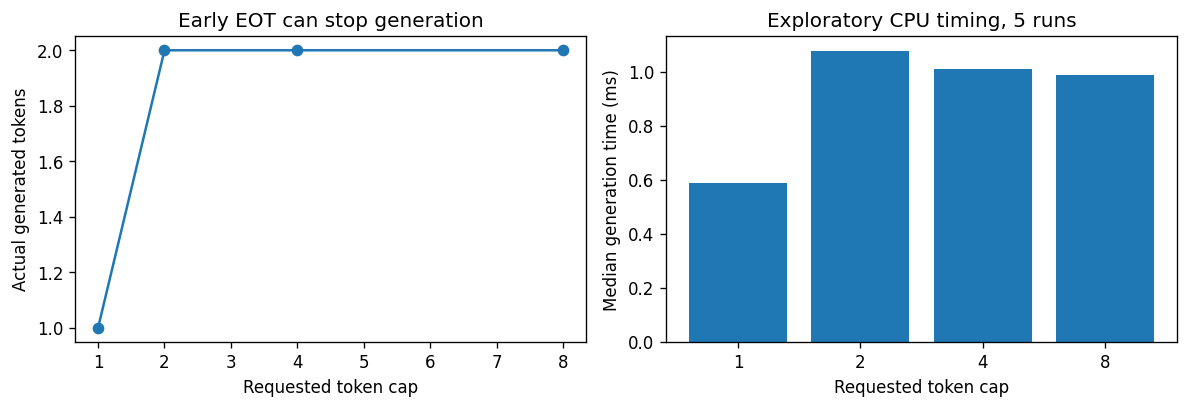

{'max_new_tokens': 1, 'median_ms': 0.5898409999645082, 'generated_tokens': 1, 'finish_reason': 'length', 'response': '3'}
{'max_new_tokens': 2, 'median_ms': 1.0775279997687903, 'generated_tokens': 2, 'finish_reason': 'eot', 'response': '3'}
{'max_new_tokens': 4, 'median_ms': 1.012389000152325, 'generated_tokens': 2, 'finish_reason': 'eot', 'response': '3'}
{'max_new_tokens': 8, 'median_ms': 0.9887930000331835, 'generated_tokens': 2, 'finish_reason': 'eot', 'response': '3'}


In [17]:
latency_rows=[]
for budget in (1,2,4,8):
    cfg=DecodeConfig(max_new_tokens=budget,greedy=True)
    reply_once("sft","1+2",cfg)  # Warm-up; exclude from measurements.
    runs=[reply_once("sft","1+2",cfg) for _ in range(5)]
    row={"max_new_tokens":budget,"median_ms":1000*float(np.median([r.elapsed_seconds for r in runs])),
         "generated_tokens":runs[0].generated_tokens,"finish_reason":runs[0].finish_reason,
         "response":runs[0].text}
    latency_rows.append(row); print(row)
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].plot([r["max_new_tokens"] for r in latency_rows],[r["generated_tokens"] for r in latency_rows],"o-")
axes[0].set(xlabel="Requested token cap",ylabel="Actual generated tokens",title="Early EOT can stop generation")
axes[1].bar([str(r["max_new_tokens"]) for r in latency_rows],[r["median_ms"] for r in latency_rows])
axes[1].set(xlabel="Requested token cap",ylabel="Median generation time (ms)",title="Exploratory CPU timing, 5 runs")
fig.tight_layout();plt.show()


## 14. Save a reproducible chat receipt

A useful diagnostic record includes checkpoint identity, tokenizer/template version, exact prefix, decoding configuration, seed, response tokens, and termination status. Save raw outputs rather than only a cleaned final answer. The transcript here is plain JSON and contains the messages you entered; use appropriate care if you later adapt it to private conversations.

We separately store the scripted interface test, real-model session, one-shot observations, and sampling experiment. A test fixture must never be mistaken for a model response. The final assertions verify that no model weights or checkpoint files changed during inference.


In [18]:
for stage,model in models.items():
    assert model_digest(model)==WEIGHTS_BEFORE[stage], f"Model weights changed: {stage}"
    assert sha256_file(CHECKPOINTS[stage])==CHECKPOINT_HASHES[stage]
    assert all(p.grad is None for p in model.parameters())
(RUN_DIR/"one_shot_observations.json").write_text(json.dumps(observations,indent=2))
(RUN_DIR/"sampling_experiment.json").write_text(json.dumps(sampling_rows,indent=2))
(RUN_DIR/"latency_experiment.json").write_text(json.dumps(latency_rows,indent=2))
manifest={"lab":"07","track":"ASCII teaching checkpoints","torch":str(torch.__version__),
    "device":DEVICE,"checkpoint_paths":{s:str(p) for s,p in CHECKPOINTS.items()},
    "checkpoint_sha256":CHECKPOINT_HASHES,"tokenizer":EXPECTED_TOKENIZER,
    "single_turn_template":"U:{user_text}\nA:","history_template":"compact-history-extension-v1",
    "context_length":24,"weight_updates":False,"repository_track":REPO_STATUS,
    "limitations":["24-token context","single-turn arithmetic training","multi-turn out of distribution",
                   "qualitative examples are not a benchmark","CPU timing is exploratory"]}
(RUN_DIR/"manifest.json").write_text(json.dumps(manifest,indent=2))
print("All model and checkpoint hashes unchanged; no gradients accumulated.")
print("Artifacts:",[p.name for p in sorted(RUN_DIR.iterdir())])


All model and checkpoint hashes unchanged; no gradients accumulated.
Artifacts: ['latency_experiment.json', 'manifest.json', 'one_shot_observations.json', 'sampling_experiment.json', 'scripted_interface_session.json', 'sft_session.json']


## 15. Independent exercises and marking rubric

Do the exercises in new cells and preserve the reference outputs. Each exercise should produce evidence, not just a code listing.

### A. Template contract — 15 points

Construct raw, compact single-turn, and compact two-turn prefixes. List their exact IDs and lengths. Add tests for an empty user message, a non-ASCII character, a malformed role order, and the unsupported compact system role. In Track B, compare `encode_prompt` with ordinary tokenization of the debug rendering.

**Acceptance:** expected IDs are checked explicitly; actual EOT IDs are distinguished from literal marker characters; no silent tokenizer substitution occurs.

### B. Decoder boundaries — 20 points

Add tests for a tied top-k cutoff, top-p crossing, immediate EOT, one-token budget, and a non-finite logit. Compare greedy output under different temperature values, then sampled output under fixed and changed seeds.

**Acceptance:** greedy output does not depend on temperature; fixed-seed replay matches on this CPU setup; the top-p crossing token remains; a finite valid distribution survives filtering. Do not require different seeds to always produce different outputs.

### C. Stateful session — 20 points

Test five sequential turns with variable message lengths. Verify exactly which pairs are pruned. Add tests for a failed generation, an empty EOT reply, and a partial length-limited reply. Check that the current question is never cut.

**Acceptance:** history changes only after a committed response; no orphan assistant turn survives pruning; rejected turns leave history unchanged. Keep application-state tests separate from model-capability examples.

### D. Repository replication — 20 points

Run raw base continuation, one-shot SFT chat, greedy GRPO chat, and the repository interactive loop. Record exact commands, checkpoint hashes, checkout commit and outputs. Show from code or captured prefixes whether the second interactive question includes the first turn.

**Acceptance:** actual repository checkpoints and tokenizer are used; unsupported flags are not invented; absent resources are labelled **not executed**, with a concrete setup plan instead of fabricated results.

### E. Decode budget and efficiency — 15 points

Repeat the latency experiment on at least two prompts with different lengths. For repository models, compare ordinary weights against `--int8` using the same examples. Keep loading time separate. If a GPU is used, synchronize timing correctly.

**Acceptance:** report actual generated tokens, stop behavior where observable, repetitions and hardware. Memory, latency and correctness are distinct metrics. A shorter or incorrect response is not automatically a speed improvement.

### F. Engineering memo — 10 points

Write 300–500 words describing your chat interface's guarantees, unsupported behaviors, observed model failures, and the next evaluation you would run. Explain why conversation history is not weight training, and why a few pleasant chat responses do not supersede Lab 06.

**Acceptance:** cite your saved records; distinguish software correctness from learned capability; identify one concrete tradeoff between response budget and retained history.


## 16. Hints, troubleshooting, and completion checklist

**Exercise A hint:** the compact one-turn prefix `U:1+2\nA:` has 8 ASCII tokens. Adding the response digit and EOT makes a completed pair 10 tokens. Repository markers tokenize differently: inspect the tokenizer instead of counting visible characters.

**Exercise B hint:** with probabilities `[0.50, 0.30, 0.15, 0.05]` and top-p 0.7, retain the first two tokens before renormalization. A threshold top-k=1 over four equal logits retains all four; argmax still chooses one deterministically.

**Exercise C hint:** snapshot the history before each failure case and compare afterward. Prefix length alone is not enough: assert the retained message contents and role order.

**Exercise D hint:** the repository's `generate_reply` begins with a new `messages=[]` inside each call. For multi-turn behavior, pass an explicitly retained list to `encode_prompt` and the shared generator.

**Exercise E hint:** a requested cap of 128 does not imply 128 generated tokens. EOT may arrive at token two, and prompt length may reduce the effective budget.

| Symptom | Check and response |
|---|---|
| Checkpoint missing | Correct the path or complete the previous lab; do not create random replacement weights |
| State-dict or tokenizer mismatch | Use the loader and template matching the checkpoint family |
| Base continues the question instead of answering | Check raw/chat mode and whether it received instruction training |
| Empty reply | Distinguish immediate EOT from exhausted context; inspect token IDs |
| “Chat” forgets previous turn | Inspect serialized messages; repository REPL is stateless |
| History disappears quickly | Compare reserved reply budget with context capacity and whole-turn lengths |
| Model echoes headers or emits odd text | Inspect raw outputs and training coverage; formatting alone cannot fix weak weights |
| Repeated samples despite different seeds | The distribution may be concentrated; inspect temperature and filters |
| A changed system prompt has little effect | Check training support; a system role is not guaranteed behavioral control |
| Notebook hangs during Run All | Leave RUN_INTERACTIVE=False and run the input cell explicitly when ready |
| Repository imports refer to another checkout | Restart kernel and configure REPO_ROOT before importing `src` |

### Definition of done

- Actual Lab checkpoint files load strictly and preserve their original hashes.
- One-shot raw and chat modes share the same tested token-generation core.
- Decoding tests cover EOT, length caps, context errors and reproducibility.
- Stateful history is clearly identified as an extension and prunes complete pairs.
- Rollback and reset behavior are tested; the interactive input loop is opt-in.
- Real-model outputs and scripted fixtures are not conflated.
- Session receipts record enough information to reproduce a request.
- The actual repository path is completed or explicitly marked not run.
- The final interpretation remains consistent with Lab 06's measured limitations.

You now have the complete educational pipeline: prepare data, build a model, pretrain, generate, post-train, evaluate, and interact. Further progress should be driven by measured failures: improve the data or training, rerun fixed evaluation, and then inspect chat behavior under the same documented protocol.


In [19]:
print("LAB 07 EXECUTION RECEIPT")
print("Real saved policies loaded:",len(models))
print("One-shot stage observations:",len(observations),"| sampled continuations:",len(sampling_rows))
print("Inference, filtering, session rollback/pruning, and scripted interface checks: passed")
print("Weights and checkpoint files unchanged: verified")
print("Actual repository track:",REPO_STATUS)
print("Human interactive input:","enabled" if RUN_INTERACTIVE else "not started; scripted loop tested")
print("Evidence directory:",RUN_DIR)


LAB 07 EXECUTION RECEIPT
Real saved policies loaded: 5
One-shot stage observations: 11 | sampled continuations: 9
Inference, filtering, session rollback/pruning, and scripted interface checks: passed
Weights and checkpoint files unchanged: verified
Actual repository track: not run
Human interactive input: not started; scripted loop tested
Evidence directory: /workspace/scratch/d20f4a09d498/lab07_runs/chat_5o39lhqo
